# Введение в Machine Learning
Belioglo Alina IASD26 R

 Практические задания на основе набора данных Iris и Intel® oneAPI AI Analytics Toolkit (AI Kit).

### Упражнение 1: Загрузка и первичный анализ данных
    Используя библиотеки `pandas` и `numpy`, загрузите файл `Iris.csv` из директории `data`. Выведите на экран:
    - Общее количество строк.
    - Имена всех колонок.
    - Типы данных для каждой колонки.

In [11]:
# Импортируем библиотеки: numpy для чисел, pandas для таблиц
import numpy as np
import pandas as pd

# Загружаем файл Iris_Data.csv из папки data
data = pd.read_csv('data/Iris.csv')

# Первые 5 строк - чтобы убедиться, что данные загрузились
data.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [12]:
# Общее количество строк (shape - это (строки, столбцы), берём первый элемент)
print('Количество строк:', data.shape[0])

# Имена всех колонок
print('Колонки:', data.columns.tolist())

# Типы данных для каждой колонки
print(data.dtypes)

Количество строк: 150
Колонки: ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']
Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species              str
dtype: object


### Упражнение 2: Очистка и преобразование текстовых данных
    Исследуйте значения в колонке `species`.
    Обратите внимание, что все они начинаются с префикса `Iris-`.
    Напишите код для удаления этого префикса во всех строках (чтобы осталось только `setosa`, `versicolor`, `virginica`).

In [13]:
# Смотрим, какие значения есть в колонке species (до очистки)
print(data['Species'].unique())

# Заменяем префикс 'Iris-' на пустую строку во всех строках колонки
data['Species'] = data['Species'].str.replace('Iris-', '', regex=False)

# Проверяем результат: должно остаться setosa, versicolor, virginica
print(data['Species'].unique())
data.head()

<StringArray>
['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
Length: 3, dtype: str
<StringArray>
['setosa', 'versicolor', 'virginica']
Length: 3, dtype: str


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,setosa
1,2,4.9,3.0,1.4,0.2,setosa
2,3,4.7,3.2,1.3,0.2,setosa
3,4,4.6,3.1,1.5,0.2,setosa
4,5,5.0,3.6,1.4,0.2,setosa


### Упражнение 3: Описательная статистика и размах (range)
    Используя метод `describe()`,
    создайте новую строку в таблице под названием `range`,
    которая вычисляет разницу между максимальным
    и минимальным значением для каждого числового столбца.

In [14]:
# describe() считает статистику по числовым колонкам
stats_df = data.describe()

# Добавляем новую строку 'range' = максимум - минимум
stats_df.loc['range'] = stats_df.loc['max'] - stats_df.loc['min']

stats_df

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000
range,149.000000,3.600000,2.400000,5.900000,2.400000


### Упражнение 4: Группировка данных по видам (Среднее и Медиана)
    "Сгруппируйте набор данных по колонке `species`
    и одновременно примените функции **среднего** (`mean`)
    и **медианы** (`median`) ко всем числовым колонкам.

In [15]:
# Группируем по виду и сразу считаем и среднее, и медиану для всех числовых колонок
data.groupby('Species').agg(['mean', 'median'])

Id        SepalLengthCm        SepalWidthCm         \
             mean median          mean median         mean median   
Species                                                             
setosa       25.5   25.5         5.006    5.0        3.418    3.4   
versicolor   75.5   75.5         5.936    5.9        2.770    2.8   
virginica   125.5  125.5         6.588    6.5        2.974    3.0   

           PetalLengthCm        PetalWidthCm         
                    mean median         mean median  
Species                                              
setosa             1.464   1.50        0.244    0.2  
versicolor         4.260   4.35        1.326    1.3  
virginica          5.552   5.55        2.026    2.0

### Упражнение 5: Расширенная агрегация с помощью словаря
    Используя метод `agg()` для сгруппированных данных,
    примените следующие правила: для `SepalLengthCm`, `SepalWidthCm` и `PetalWidthCm`
    вычислите среднее и медиану, а для `PetalLengthCm`- только максимальное значение (`max`).

In [16]:
# Словарь правил: для каждой колонки - какие функции применить
agg_dict = {
    'SepalLengthCm': ['mean', 'median'],
    'SepalWidthCm': ['mean', 'median'],
    'PetalWidthCm': ['mean', 'median'],
    'PetalLengthCm': 'max' # только максимум
}

data.groupby('Species').agg(agg_dict)

SepalLengthCm        SepalWidthCm        PetalWidthCm         \
                    mean median         mean median         mean median   
Species                                                                   
setosa             5.006    5.0        3.418    3.4        0.244    0.2   
versicolor         5.936    5.9        2.770    2.8        1.326    1.3   
virginica          6.588    6.5        2.974    3.0        2.026    2.0   

           PetalLengthCm  
                     max  
Species                   
setosa               1.9  
versicolor           5.1  
virginica            6.9

### Упражнение 6: Визуализация данных с помощью Matplotlib
    Импортируйте `matplotlib.pyplot`
    и постройте диаграмму рассеяния (scatter plot),
    отражающую зависимость `SepalLengthCm` (ось X) от `SepalWidthCm` (ось Y).
    Добавьте подписи осей и заголовок.

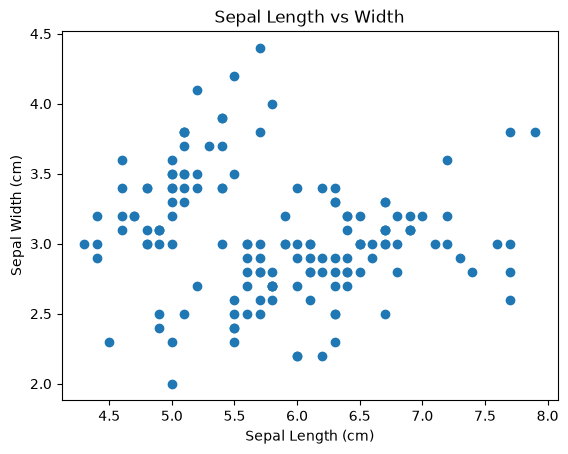

In [17]:
import matplotlib.pyplot as plt
%matplotlib inline

# Диаграмма рассеяния: SepalLengthCm по оси X, SepalWidthCm по оси Y
plt.scatter(data['SepalLengthCm'], data['SepalWidthCm'])

# Подписи осей и заголовок
plt.xlabel('Sepal Length (cm)')
plt.ylabel('Sepal Width (cm)')
plt.title('Sepal Length vs Width')
plt.show()

### Упражнение 7: Подсчет частоты видов
    "Используйте специальный метод Pandas,
    чтобы узнать точное количество записей
    для каждого отдельного вида в очищенном наборе данных.

In [18]:
# value_counts() считает, сколько раз встречается каждое значение
data['Species'].value_counts()

Species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

### Упражнение 8: Ускорение Scikit-learn с помощью Intel® Extension
    Напишите строки кода, которые необходимо выполнить сразу
    после импорта библиотеки `sklearn` для включения оптимизации oneDAL.

In [19]:
from sklearnex import patch_sklearn
patch_sklearn()

import sklearn

Extension for Scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


### Упражнение 9: Фреймворки в Machine Learning
    Основываясь на вводных материалах, объясните,
    почему фреймворки - это больше, чем просто библиотеки,
    и какую материальную пользу приносит оптимизация гиперпараметров.

**Ответ:**

Фреймворк это больше, чем библиотека. Библиотека- это просто набор готового кода, который мы вызываем, когда нужно. Фреймворк же задаёт структуру: он влияет на то, как мы пишем и организуем свой код (например, в scikit-learn у всех моделей единый порядок работы: создать модель, обучить, получить предсказание).

Оптимизация (в том числе оптимизация гиперпараметров) даёт не только ускорение. Код, который работает быстрее, просто удобнее, но в прикладных задачах есть и более ощутимая польза: можно за то же время проверить больше вариантов настроек модели и подобрать лучшие, а значит получить более точную модель, при этом тратя меньше вычислительных ресурсов и времени.

### Упражнение 10: Предварительные требования курса
    Перечислите как минимум три базовых направления
    (в математике и программировании),
    необходимых для успешного прохождения курса по Machine Learning.

**Ответ:**

Для успешного прохождения курса по Machine Learning нужны следующие базовые направления:

1. **Программирование на Python** - чтобы писать код, работать с данными (pandas, numpy) и строить графики.
2. **Математический анализ** - производные и градиенты нужны, чтобы понимать, как обучаются модели.
3. **Линейная алгебра** - векторы и матрицы, на которых строятся данные и алгоритмы.
4. **Статистика** - среднее, дисперсия, распределения, корреляция.

## Упражнение 11: Продвинутая визуализация распределений с Matplotlib (Гистограммы)
    Используя Matplotlib, постройте фигуру с двумя подграфиками (subplots)
    рядом друг с другом (1 строка, 2 колонки):,
    - На первом графике отобразите гистограмму распределения для `PetalLengthCm`.,
    - На втором графике отобразите гистограмму распределения для `PetalWidthCm`.,
    Добавьте заголовки и подписи к осям для каждого графика.

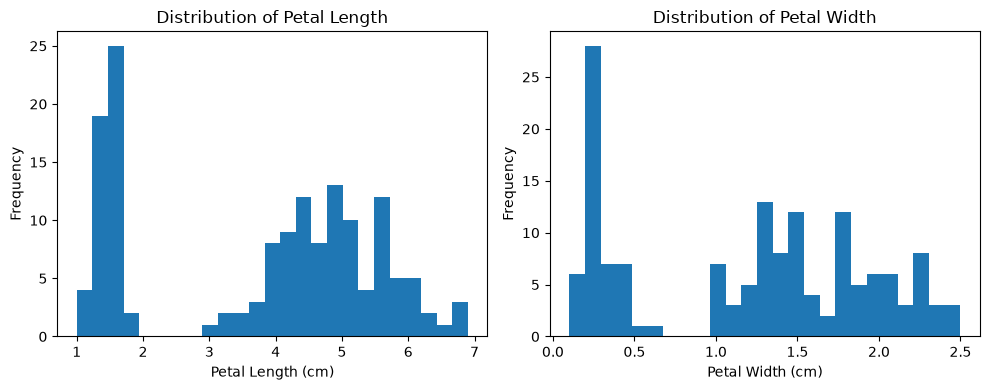

In [20]:
import matplotlib.pyplot as plt
# Фигура с двумя графиками рядом (1 строка, 2 колонки)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Первый график: распределение длины лепестка
axes[0].hist(data['PetalLengthCm'], bins=25)
axes[0].set_title('Distribution of Petal Length')
axes[0].set_xlabel('Petal Length (cm)')
axes[0].set_ylabel('Frequency')

# Второй график: распределение ширины лепестка
axes[1].hist(data['PetalWidthCm'], bins=25)
axes[1].set_title('Distribution of Petal Width')
axes[1].set_xlabel('Petal Width (cm)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

### Упражнение 12: Исследование данных с помощью Seaborn (Pairplot)
    Импортируйте библиотеку `seaborn`
    и постройте парную матрицу графиков (`sns.pairplot`)
    для всего набора данных Iris,
    раскрасив точки в зависимости от вида растения (`Species`).

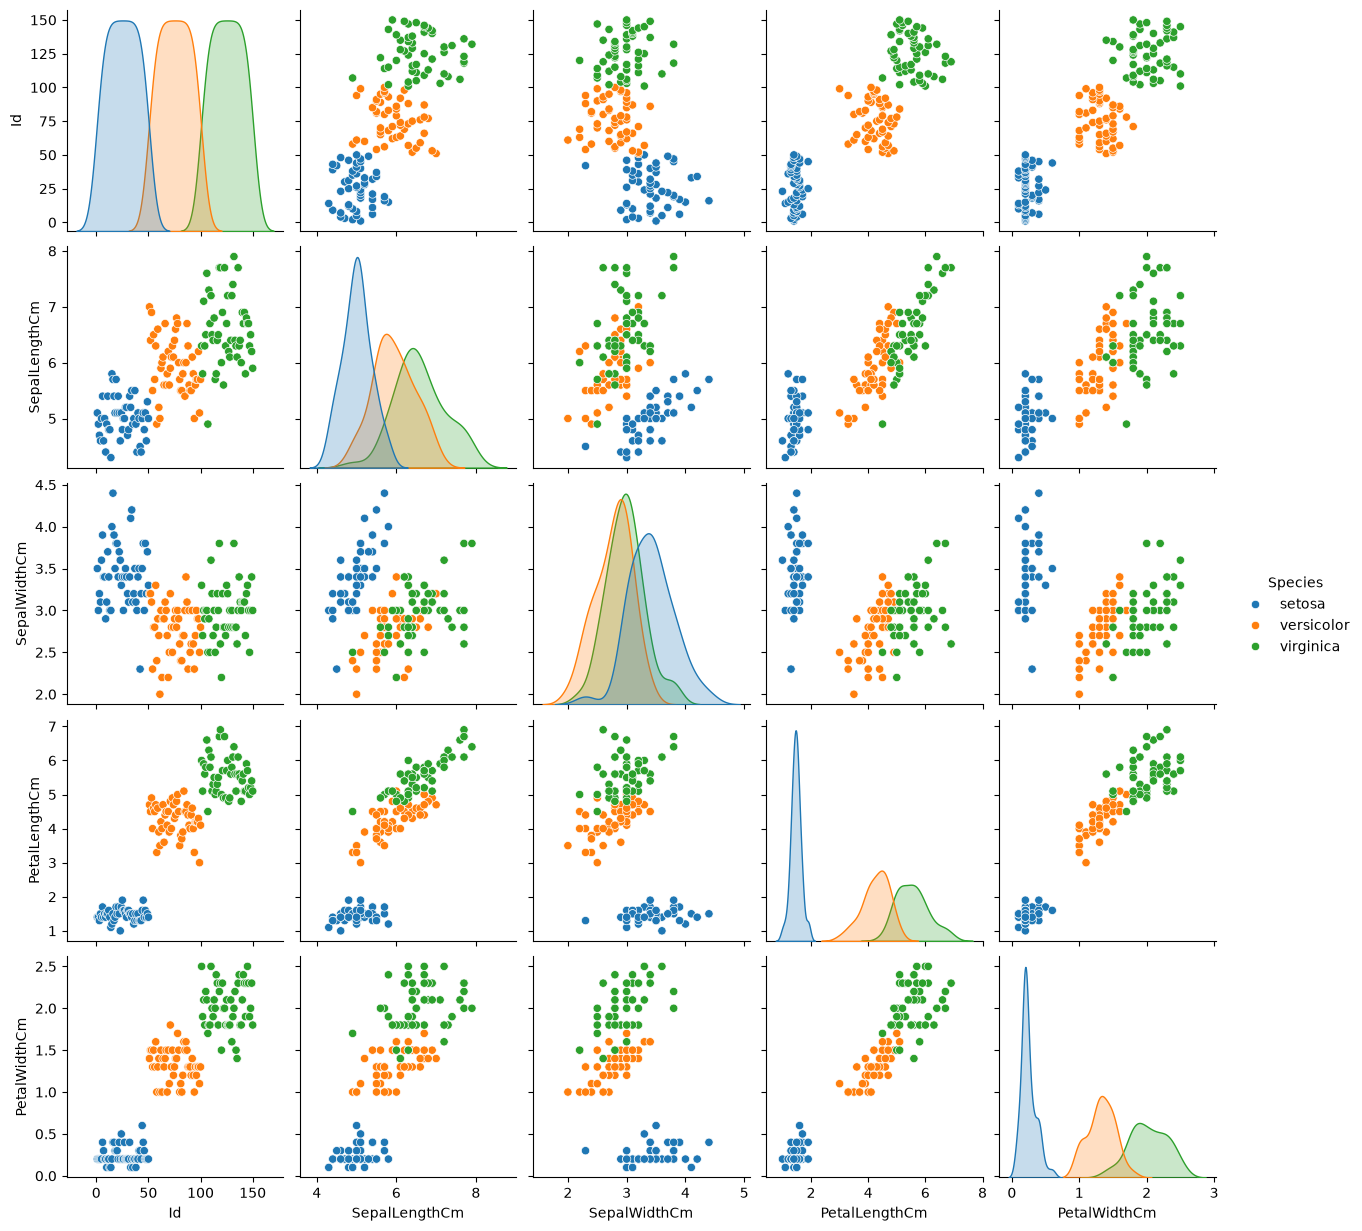

In [25]:
import seaborn as sns

# Парная матрица графиков, цвет точек зависит от вида
sns.pairplot(data, hue='Species')
plt.show()

### Упражнение 13: Анализ выбросов через Boxplot (Seaborn)
    Используя библиотеку Seaborn, постройте график «ящик с усами» (`sns.boxplot`),
    чтобы сравнить распределение длины лепестков (`PetalLengthCm`) для каждого отдельного вида (`Species`).

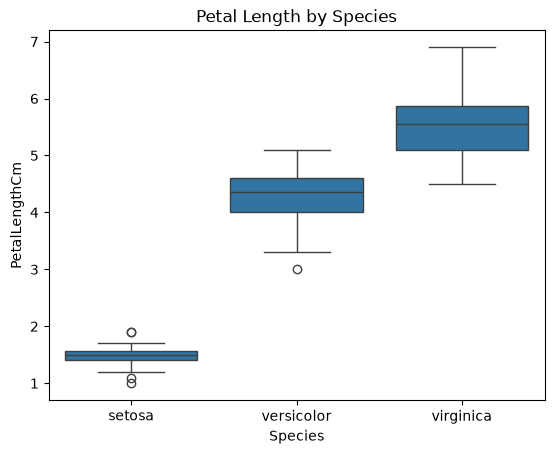

In [26]:
# Боксплот: длина лепестков для каждого вида
sns.boxplot(x='Species', y='PetalLengthCm', data=data)
plt.title('Petal Length by Species')
plt.show()

### Упражнение 14: Тепловая карта корреляций (Seaborn Heatmap)
    Вычислите корреляционную матрицу числовых признаков
    с помощью метода `corr()`, а затем визуализируйте её в виде тепловой карты (`sns.heatmap`),
    включив отображение числовых значений внутри ячеек (`annot=True`).

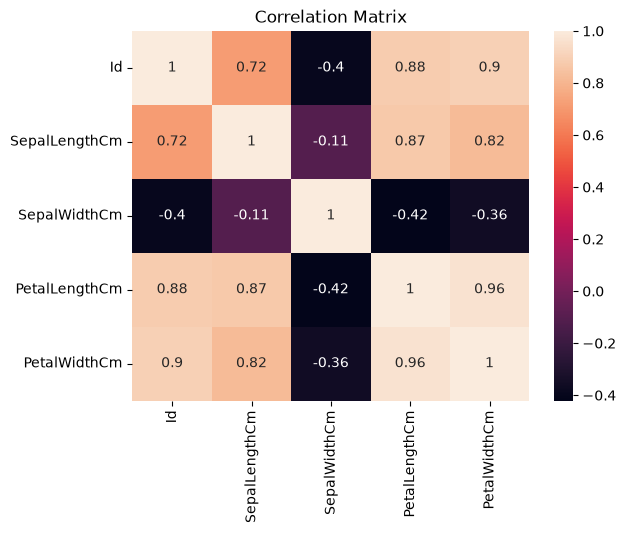

In [28]:
# Корреляционная матрица только по числовым признакам (Species убираем)
corr = data.drop(columns='Species').corr()

# Тепловая карта с числами внутри ячеек
sns.heatmap(corr, annot=True)
plt.title('Correlation Matrix')
plt.show()